# Multimodal RAG - staged pipeline demonstration version 2

PDF text, tables and figures are extracted with PyMuPDF, figures described by Gemini, embedded locally with MiniLM and served from Chroma + SQLite by `rag_pipeline.py`.

> Sections G-J call Gemini only when `RUN_MODEL_CALLS` and `EXTRACTION_REVIEW_APPROVED` are both `True` (section A); the free tier caps requests per day.

## A. Setup and configuration

Loads `rag_pipeline` and `.env`; API keys are reported as set or not set, never printed.

In [1]:
import os
import sys
import time
from collections import Counter
from pathlib import Path

# Locate the project by looking for rag_pipeline.py, so this works whether the
# kernel started in the project directory, a parent, or somewhere else.
PROJECT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "rag_pipeline.py").is_file()),
    Path.cwd(),
)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import importlib
import sys

# Ensure the project directory has import priority.
project_path = str(PROJECT_DIR.resolve())

if project_path in sys.path:
    sys.path.remove(project_path)

sys.path.insert(0, project_path)

# Remove any previously cached version.
if "rag_pipeline" in sys.modules:
    del sys.modules["rag_pipeline"]

importlib.invalidate_caches()
import rag_pipeline as rp

# Verify that the correct file was loaded.
print("Loaded pipeline:", rp.__file__)
print(
    "Figure renderer available:",
    callable(getattr(rp, "figure_image_bytes", None))
)

assert callable(getattr(rp, "figure_image_bytes", None)), (
    "figure_image_bytes() not found. Check that the updated rag_pipeline.py "
    "is saved in PROJECT_DIR."
)

PDF_PATH = PROJECT_DIR / "BCS703_module_1.pdf"  # point this at any other PDF
QUESTION = "LinearCongruential Generators"
DRAWING_REVIEW_PAGE = 69
# ---- safety switches -----------------------------------------------------
RUN_MODEL_CALLS = True  
EXTRACTION_REVIEW_APPROVED = True

MODELS_ENABLED = RUN_MODEL_CALLS and EXTRACTION_REVIEW_APPROVED
SKIP_NOTE = (
    "skipped: this cell calls paid APIs. Set RUN_MODEL_CALLS and "
    "EXTRACTION_REVIEW_APPROVED to True in section A to enable it."
)
# Kept across re-runs, so re-running this cell never opens a second Chroma client.
retriever = globals().get("retriever")
report = globals().get("report")
print("model calls:", "ENABLED" if MODELS_ENABLED else "disabled")

Loaded pipeline: D:\MultimodalRAG\rag_pipeline.py
Figure renderer available: True
model calls: ENABLED


In [2]:
print(f"project dir    : {PROJECT_DIR}")
print(f"pdf            : {PDF_PATH.name}   exists={PDF_PATH.is_file()}")
print(f"chroma dir     : {rp.CHROMA_DIR}")
print(f"state database : {rp.STATE_DB}")
print(f"fingerprint    : {rp.config_fingerprint()}")
print()
print(f"extractor  : {rp.EXTRACTOR}  (local, no OCR, no layout model)")
print(f"embeddings : {rp.EMBEDDING_MODEL}  (local CPU, no API)")
print(f"gemini     : {rp.ANSWER_MODEL}  (figure summaries, grading, answers)")
print(f"figures    : summaries {'ON' if rp.IMAGE_SUMMARIES else 'OFF'}  (IMAGE_SUMMARIES)")
print(f"chunking   : {rp.CHUNK_CHARS} chars, {rp.CHUNK_OVERLAP} overlap")
print(f"captions   : {rp.CAPTION_CHARS} chars each side of a figure, above a table")
print(f"tables     : detection {'ON' if rp.FIND_TABLES else 'OFF'}  (FIND_TABLES)")
print()
# Presence only. The values themselves are never printed or logged.
for name in ("GEMINI_API_KEY", "GOOGLE_API_KEY"):
    print(f"{name:15}: {'set' if os.getenv(name) else 'NOT SET'}")

project dir    : d:\MultimodalRAG
pdf            : BCS703_module_1.pdf   exists=True
chroma dir     : D:\MultimodalRAG\chroma_db
state database : D:\MultimodalRAG\rag_state.sqlite3
fingerprint    : 5f33e6ae0d4cd836

extractor  : pymupdf  (local, no OCR, no layout model)
embeddings : sentence-transformers/all-MiniLM-L6-v2  (local CPU, no API)
gemini     : gemini-flash-lite-latest  (figure summaries, grading, answers)
figures    : summaries ON  (IMAGE_SUMMARIES)
chunking   : 1000 chars, 150 overlap
captions   : 400 chars each side of a figure, above a table
tables     : detection ON  (FIND_TABLES)

GEMINI_API_KEY : set
GOOGLE_API_KEY : NOT SET


## B. PDF extraction

Local PyMuPDF parse into text chunks, tables and raster or vector figures - no API calls.

In [3]:
started = time.perf_counter()
# summarise_images=False keeps section B offline: the vision call that writes a
# figure's description is metered, and nothing above the section F gate spends.
texts, tables, images = rp.partition_document(str(PDF_PATH), summarise_images=False)
elapsed = time.perf_counter() - started

print(f"parsed in {elapsed:.1f}s")
print(f"text chunks : {len(texts)}")
print(f"tables      : {len(tables)}")
print(f"figures     : {len(images)}")

raster_count = sum(
    image.get("extraction_method", "raster_xref") != "vector_drawing"
    for image in images
)

vector_count = sum(
    image.get("extraction_method") == "vector_drawing"
    for image in images
)

print(f"raster images  : {raster_count}")
print(f"vector drawings: {vector_count}")

seen_pages = sorted(
    {
        page
        for page in (
            [getattr(c.metadata, "page_number", None) for c in (*texts, *tables)]
            + [im.get("page_number") for im in images]
        )
        if page is not None
    }
)
print(f"pages       : {len(seen_pages)} distinct, "
      f"{seen_pages[0] if seen_pages else '-'} to {seen_pages[-1] if seen_pages else '-'}")

for label, items in (("text chunks", texts), ("tables", tables), ("figures", images)):
    if not items:
        print(f"WARNING: no {label} were extracted")

over = [len(c.text) for c in texts if len(c.text) > rp.CHUNK_CHARS]
if over:
    print(f"WARNING: {len(over)} chunks exceed CHUNK_CHARS; the tail is embedded blind")

parsed in 14.4s
text chunks : 107
tables      : 3
figures     : 28
raster images  : 28
vector drawings: 0
pages       : 45 distinct, 1 to 45


In [4]:
# Content-type distribution per page, so a page that lost its tables or images
# is visible rather than averaged away.
per_page = Counter()

for kind, items in (("text", texts), ("table", tables)):
    for item in items:
        page = getattr(item.metadata, "page_number", None)
        per_page[(page, kind)] += 1

for image in images:
    page = image.get("page_number")
    method = image.get("extraction_method", "raster_xref")

    kind = "vector" if method == "vector_drawing" else "raster"
    per_page[(page, kind)] += 1

record_pages = sorted({
    page for page, _ in per_page if page is not None
})

print(f"{'page':>5} {'text':>5} {'table':>6} {'raster':>7} {'vector':>7}")

for page in record_pages:
    row = [
        per_page[(page, kind)]
        for kind in ("text", "table", "raster", "vector")
    ]

    print(
        f"{page:>5} {row[0]:>5} {row[1]:>6} "
        f"{row[2]:>7} {row[3]:>7}"
    )

 page  text  table  raster  vector
    1     1      0       2       0
    2     2      0       1       0
    3     3      0       0       0
    4     2      0       1       0
    5     2      0       1       0
    6     3      0       0       0
    7     2      1       0       0
    8     3      1       0       0
    9     2      0       0       0
   10     1      0       1       0
   11     2      1       0       0
   12     2      0       1       0
   13     3      0       0       0
   14     3      0       0       0
   15     1      0       3       0
   16     2      0       3       0
   17     2      0       4       0
   18     2      0       1       0
   19     4      0       0       0
   20     3      0       0       0
   21     3      0       0       0
   22     3      0       0       0
   23     2      0       0       0
   24     2      0       1       0
   25     3      0       0       0
   26     3      0       0       0
   27     4      0       0       0
   28     3      0  

## C. Extracted text preview

Text chunks exactly as extracted, with page numbers.

In [5]:
PREVIEW_CHARS = 700


def show_text(index, chars=PREVIEW_CHARS):
    """Print one extracted text chunk with its boundaries and page number."""
    chunk = texts[index]
    page = getattr(chunk.metadata, "page_number", None)
    body = chunk.text or ""
    print(f"--- BEGIN text chunk {index} | page={page} | {len(body)} chars ---")
    print(body[:chars] + ("\n[...truncated for preview]" if len(body) > chars else ""))
    print(f"--- END text chunk {index} ---\n")


for i in range(min(3, len(texts))):
    show_text(i)

empty = [i for i, c in enumerate(texts) if not (c.text or "").strip()]
if empty:
    print(f"WARNING: empty text chunks at indices {empty}")
print(f"{len(texts)} text chunks in total. Inspect any other with show_text(<index>).")

--- BEGIN text chunk 0 | page=1 | 749 chars ---
1 | P a g e 
 
 
 
 
MODULE 1 
 
 
Model for Network Security 
When two parties (called principals) exchange a message over the Internet, a logical 
information channel is established using communication protocols like TCP/IP. Security 
becomes necessary to guard this communication from opponents who may attempt to 
compromise: 
• 
Confidentiality (unauthorized access) 
• 
Authenticity (verifying sender identity) 
• 
Integrity (ensuring data is not altered) 
To achieve security, two components are typically used: 
1. Security Transformation: 
Example – Encryption scrambles the message; authentication codes verify sender identity. 
2. Secret Information: 
 
 
Shared encryption keys are used t
[...truncated for preview]
--- END text chunk 0 ---

--- BEGIN text chunk 1 | page=2 | 997 chars ---
2 | P a g e 
 
 
 
 
unknown to the opponent. 
In some cases, a trusted third party is involved: 
• For distributing secret keys securely 
• For resol

In [6]:
# Inspect additional chunks: change the range, or call show_text(<index>).
for i in range(3, min(6, len(texts))):
    show_text(i, chars=400)

--- BEGIN text chunk 3 | page=3 | 941 chars ---
3 | P a g e 
 
 
 
 
o Password-based logins 
o Antivirus screening logic 
2. Internal Controls: 
o Monitor system activity 
o Analyze data to detect intruders or malicious behavior 
 
These systems help detect, prevent, and respond to unauthorized access 
 
 
Classical Encryption Techniques 
 
Symmetric encryption, also referred to as conventional encryption or single-key encryption, 
was the onl
[...truncated for preview]
--- END text chunk 3 ---

--- BEGIN text chunk 4 | page=3 | 978 chars ---
the computer era. Finally, we look briefly at a different approach known as steganography. 
Chapter 3 examines the most widely used symmetric cipher: DES. 
. 
Before beginning, we define some terms. An original message is known as the plaintext, while 
the coded message is called the ciphertext. The process of converting from plaintext to 
ciphertext is known as enciphering or encryption; restorin
[...truncated for preview]
--- END text chunk 4 -

## D. Extracted table inspection

Each recovered table grid beside its original PDF page.

In [7]:
from IPython.display import HTML, Image as ShowImage, display

BORDERS = (
    "<style>.nbtab table{border-collapse:collapse;font-size:12px}"
    ".nbtab td,.nbtab th{border:1px solid #888;padding:3px 6px}</style>"
)


def render_page(page_number, dpi=110):
    """Rasterise one page with PyMuPDF. Poppler and pdf2image are gone."""
    import pymupdf

    try:
        with pymupdf.open(PDF_PATH) as document:
            return document[page_number - 1].get_pixmap(dpi=dpi).tobytes("png")
    except Exception as exc:
        print(f"(could not render page {page_number}: {type(exc).__name__}: {exc})")
        return None


def image_tag(png_bytes, width=430):
    """PNG bytes as an inline <img>, so a page can sit beside the HTML table."""
    import base64

    data = base64.b64encode(png_bytes).decode()
    return (
        f'<img src="data:image/png;base64,{data}" '
        f'style="width:{width}px;border:1px solid #ccc">'
    )


def show_table(index):
    """Extracted table and its source PDF page, side by side."""
    table = tables[index]
    page = getattr(table.metadata, "page_number", None)
    html = getattr(table.metadata, "text_as_html", None)

    display(HTML(
        f"<h4>Table {index} &mdash; page {page} &mdash; "
        f"text_as_html {'present' if html else '<b>MISSING</b>'}</h4>"
    ))

    if html:
        cells = html.count("<td") + html.count("<th")
        print(f"rows in HTML: {html.count('<tr')}, cells: {cells}")
        extracted = f'<div class="nbtab" style="flex:1;overflow-x:auto">{BORDERS}{html}</div>'
    else:
        print("no text_as_html; the flattened text is all that was extracted:")
        print(getattr(table, "text", ""))
        extracted = f'<pre style="flex:1">{getattr(table, "text", "")}</pre>'

    rendered = render_page(page) if page else None
    original = image_tag(rendered) if rendered is not None else "<i>page not rendered</i>"
    display(HTML(
        '<div style="display:flex;gap:16px;align-items:flex-start">'
        f"{extracted}<div>{original}</div></div>"
    ))

    print("indexed text (lead-in prose, then the flattened cells), verbatim:")
    print(getattr(table, "text", "")[:900])

rows in HTML: 5, cells: 10


TypesofAttacksonEncryptedMessages,TypeofAttackKnowntoCryptanalyst
Ciphertextonly,• Encryptionalgorithm • Ciphertext
Knownplaintext,• Encryptionalgorithm • Ciphertext • One or more plaintext -cipher text pairsformedwiththesecretkey
Chosenplaintext,"• Encryptionalgorithm • Ciphertext • Plaintext message chosen by cryptanalyst together with its , corresponding ciphertextgenerated withthesecretkey"
Chosenciphertext,"• Encryptionalgorithm • Ciphertext • Purportedciphertext chosenby cryptanalyst together with its , corresponding decryptedplaintext generated withthesecretkey"

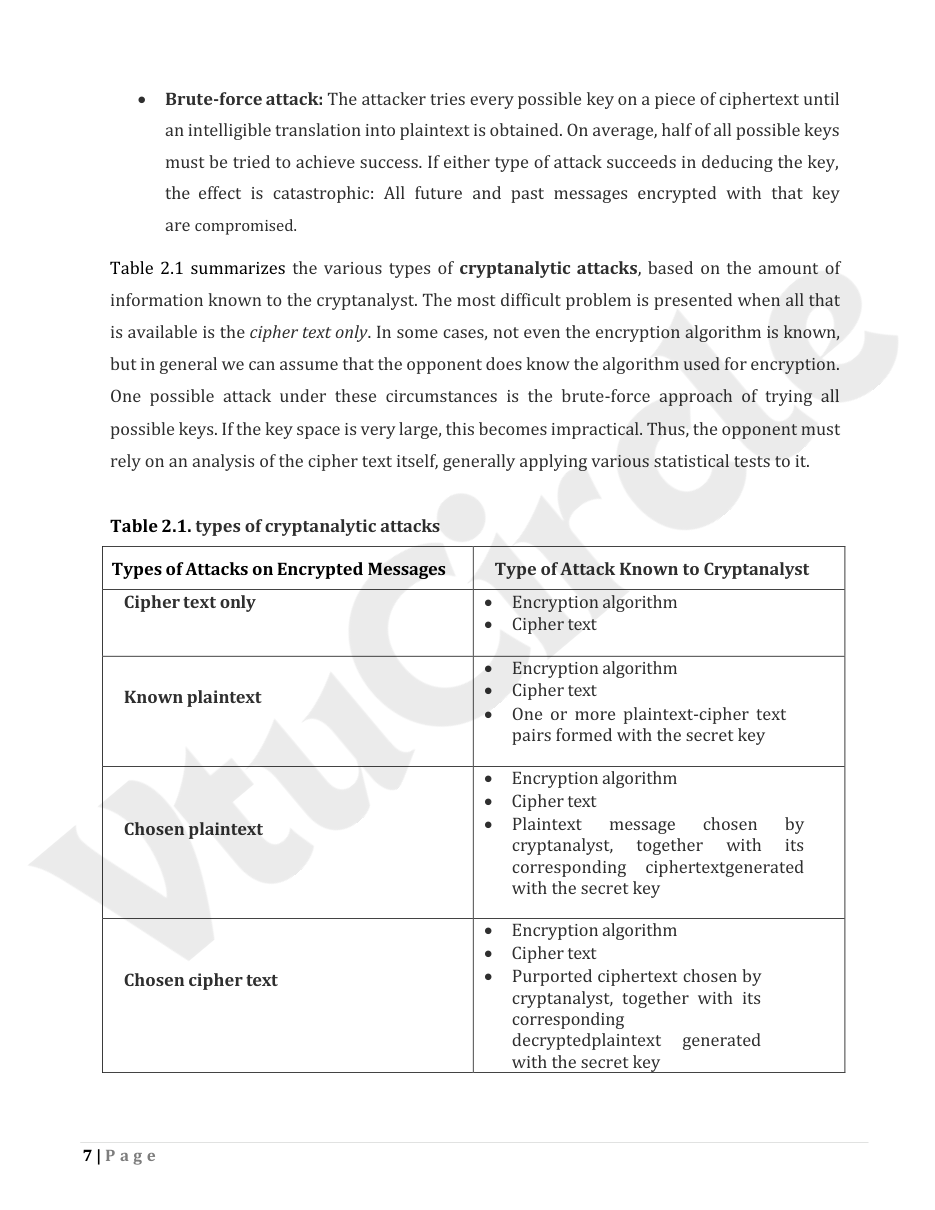

indexed text (lead-in prose, then the flattened cells), verbatim:
e that the opponent does know the algorithm used for encryption. One possible attack under these circumstances is the brute-force approach of trying all possible keys. If the key space is very large, this becomes impractical. Thus, the opponent must rely on an analysis of the cipher text itself, generally applying various statistical tests to it. Table 2.1. types of cryptanalytic attacks
TypesofAttacksonEncryptedMessages | TypeofAttackKnowntoCryptanalyst
Ciphertextonly | • Encryptionalgorithm • Ciphertext
Knownplaintext | • Encryptionalgorithm • Ciphertext • One or more plaintext -cipher text pairsformedwiththesecretkey
Chosenplaintext | • Encryptionalgorithm • Ciphertext • Plaintext message chosen by cryptanalyst together with its , corresponding ciphertextgenerated withthesecretkey
Chosenciphertext | • Encryptionalgorithm • Ciphertext • Purportedciphertext chosenby cryptanalyst togethe


rows in HTML: 1, cells: 2


Chosentext,"• Encryptionalgorithm • Ciphertext • Plaintext message chosen by cryptanalyst together with its , corresponding • ciphertextgeneratedwiththesecretkey • Purported ciphertext chosen by cryptanalyst together with its , corresponding decrypted plaintext generated with the secretkey"

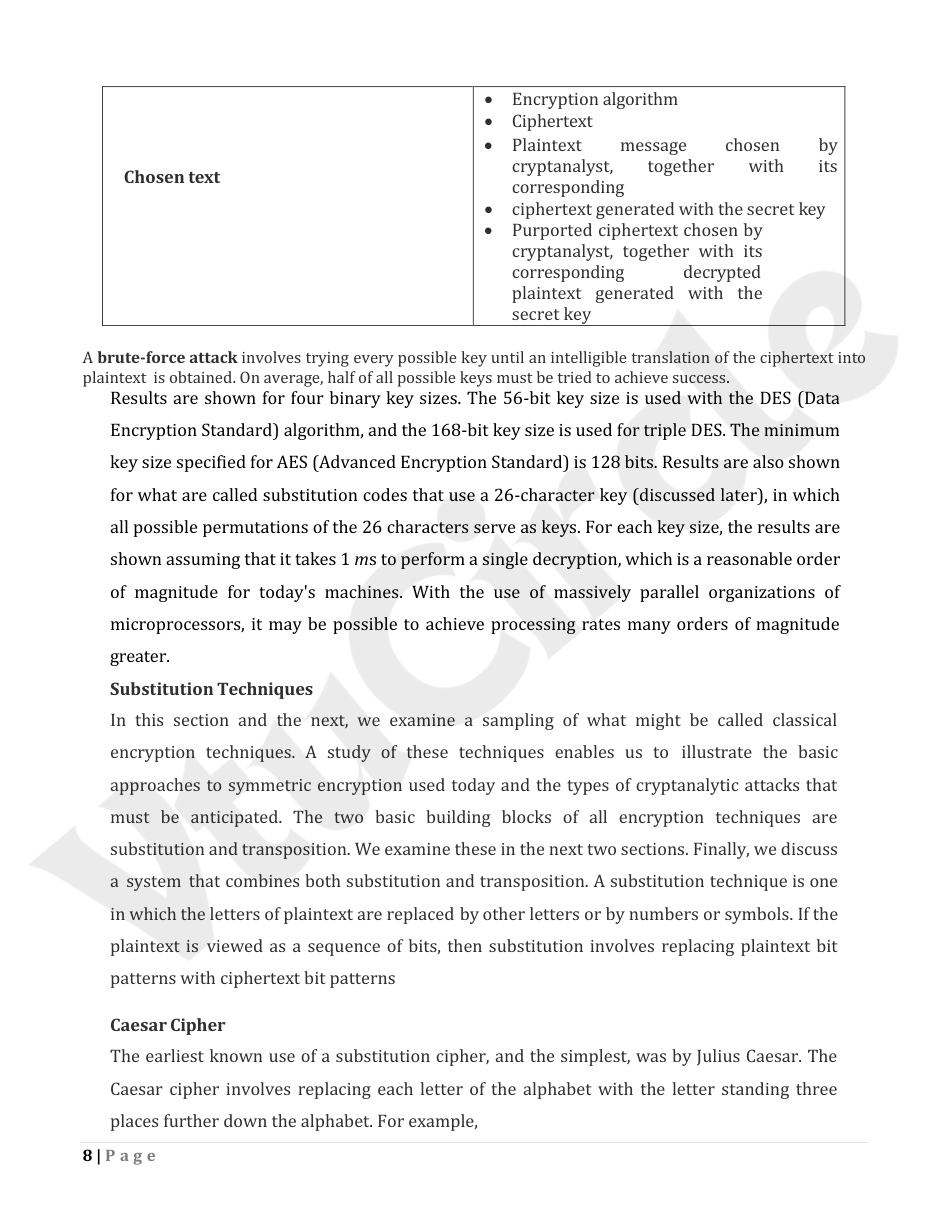

indexed text (lead-in prose, then the flattened cells), verbatim:
Chosentext | • Encryptionalgorithm • Ciphertext • Plaintext message chosen by cryptanalyst together with its , corresponding • ciphertextgeneratedwiththesecretkey • Purported ciphertext chosen by cryptanalyst together with its , corresponding decrypted plaintext generated with the secretkey


rows in HTML: 6, cells: 30


P1333 .,H583 .,F333 .,B167 .,C000 .
Z1167 .,D500 .,W333 .,G167 .,K000 .
S833 .,E500 .,Q250 .,Y167 .,L000 .
U833 .,V417 .,T250 .,I083 .,N000 .
O750 .,X417 .,A167 .,J083 .,R000 .
M667 .,,,,

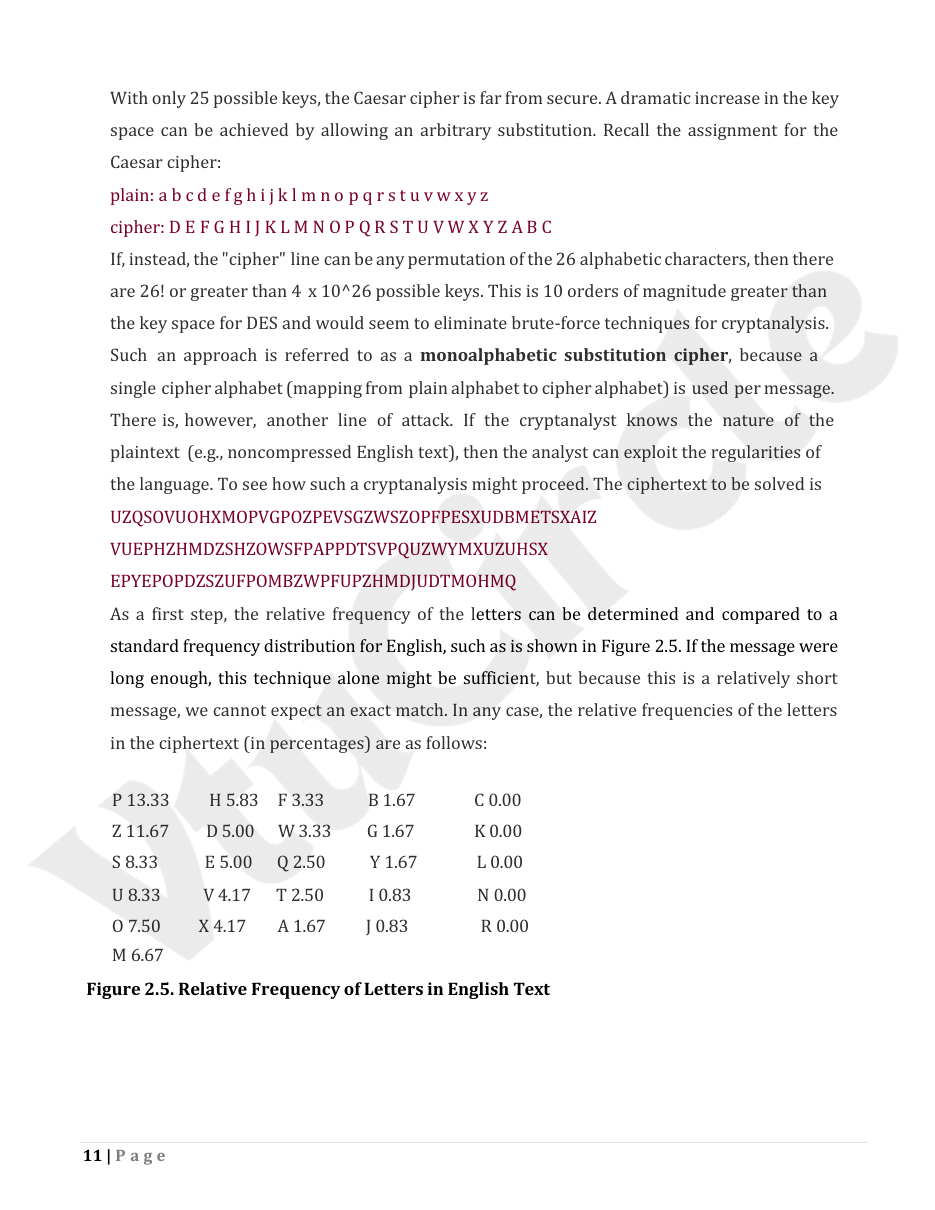

indexed text (lead-in prose, then the flattened cells), verbatim:
ency of the letters can be determined and compared to a standard frequency distribution for English, such as is shown in Figure 2.5. If the message were long enough, this technique alone might be sufficient, but because this is a relatively short message, we cannot expect an exact match. In any case, the relative frequencies of the letters in the ciphertext (in percentages) are as follows:
P1333 . | H583 . | F333 . | B167 . | C000 .
Z1167 . | D500 . | W333 . | G167 . | K000 .
S833 . | E500 . | Q250 . | Y167 . | L000 .
U833 . | V417 . | T250 . | I083 . | N000 .
O750 . | X417 . | A167 . | J083 . | R000 .
M667 . |  |  |  |


In [8]:
for index in range(len(tables)):
    show_table(index)
    print("=" * 78)

## E. Extracted figure gallery

Raster images (by xref) and vector drawings (by bounding box), both rendered with `figure_image_bytes()`.

Figure index : 0
Page         : 1
Method       : raster_xref
MIME type    : image/jpeg
Image hash   : 8f25c46bf73d6b7b
XRef         : 17
Caption      : MODULE 1 1 | P a g e Model for Network Security When two parties (called principals) exchange a message over the Internet, a logical information channel is established using communication protocols like TCP/IP. Security becomes necessary to guard this communication from opponents who may attempt to 
Gemini summary: (not written yet - section G)


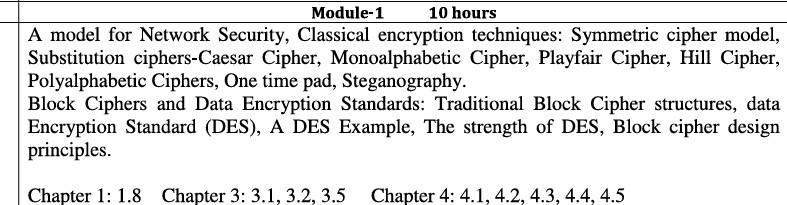

----------------------------------------------------------------------
Figure index : 1
Page         : 1
Method       : raster_xref
MIME type    : image/jpeg
Image hash   : 461ad5f0056b9a34
XRef         : 18
Caption      : his communication from opponents who may attempt to compromise: • Confidentiality (unauthorized access) • Authenticity (verifying sender identity) • Integrity (ensuring data is not altered) To achieve security, two components are typically used: 1. Security Transformation: Example – Encryption scram
Gemini summary: (not written yet - section G)


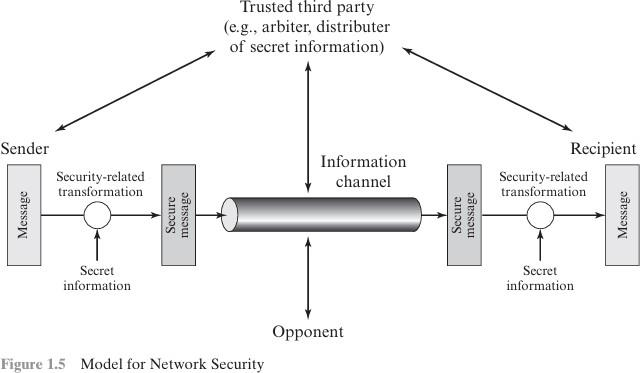

----------------------------------------------------------------------
Figure index : 2
Page         : 2
Method       : raster_xref
MIME type    : image/jpeg
Image hash   : abdedc9d1daaa314
XRef         : 35
Caption      : s • Cybercriminals: Steal data or money (e.g., credit card fraud) Two main types of software threats: 1. Information Access Threats: Accessing or modifying data illegally 2. Service Threats: Preventing legitimate users from accessing services o Viruses and Worms are common examples o These can be sp
Gemini summary: (not written yet - section G)


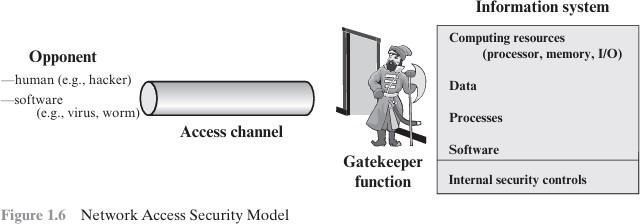

----------------------------------------------------------------------
Figure index : 3
Page         : 4
Method       : raster_xref
MIME type    : image/jpeg
Image hash   : 1b093f657c961c78
XRef         : 42
Caption      : en message, two different keys will produce two different cipher texts. The cipher text is an apparently random stream of data and, as it stands, is unintelligible. Decryption algorithm: This is essentially the encryption algorithm run in reverse. It takes the cipher text and the secret key and prod
Gemini summary: (not written yet - section G)


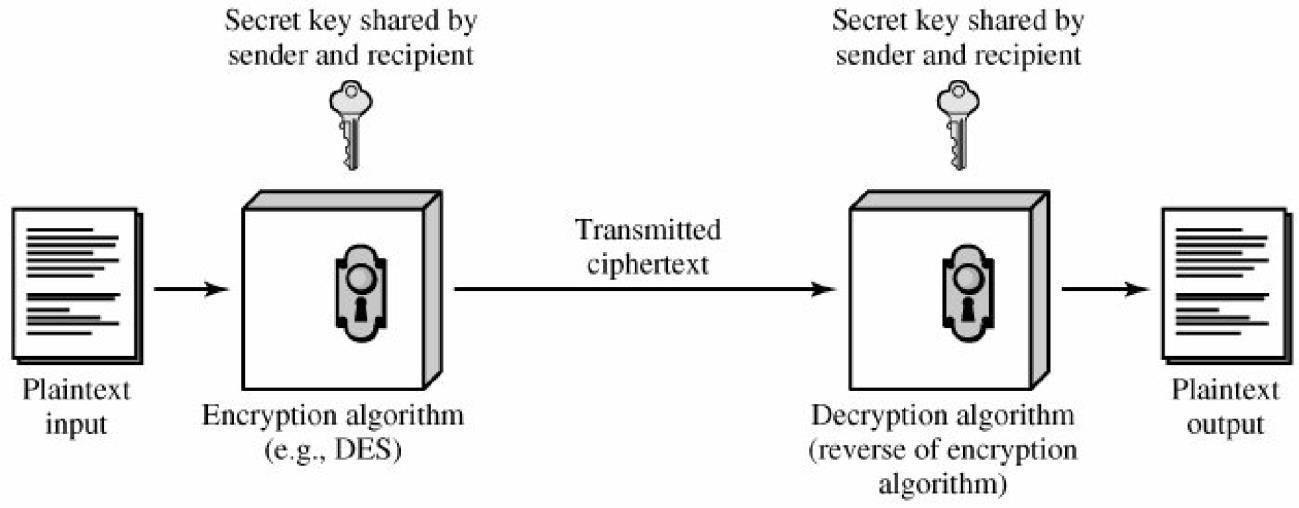

----------------------------------------------------------------------
Figure index : 4
Page         : 5
Method       : raster_xref
MIME type    : image/jpeg
Image hash   : 6280b9c0e3f24036
XRef         : 49
Caption      : sted of the 26 capital letters. Nowadays, the binary alphabet {0, 1} is typically used. For encryption, a key of the form K = [K1, K2, ..., KJ] is generated. If the key is generated at the message source, then it must also be provided to the destination by means of some secure channel. Alternatively
Gemini summary: (not written yet - section G)


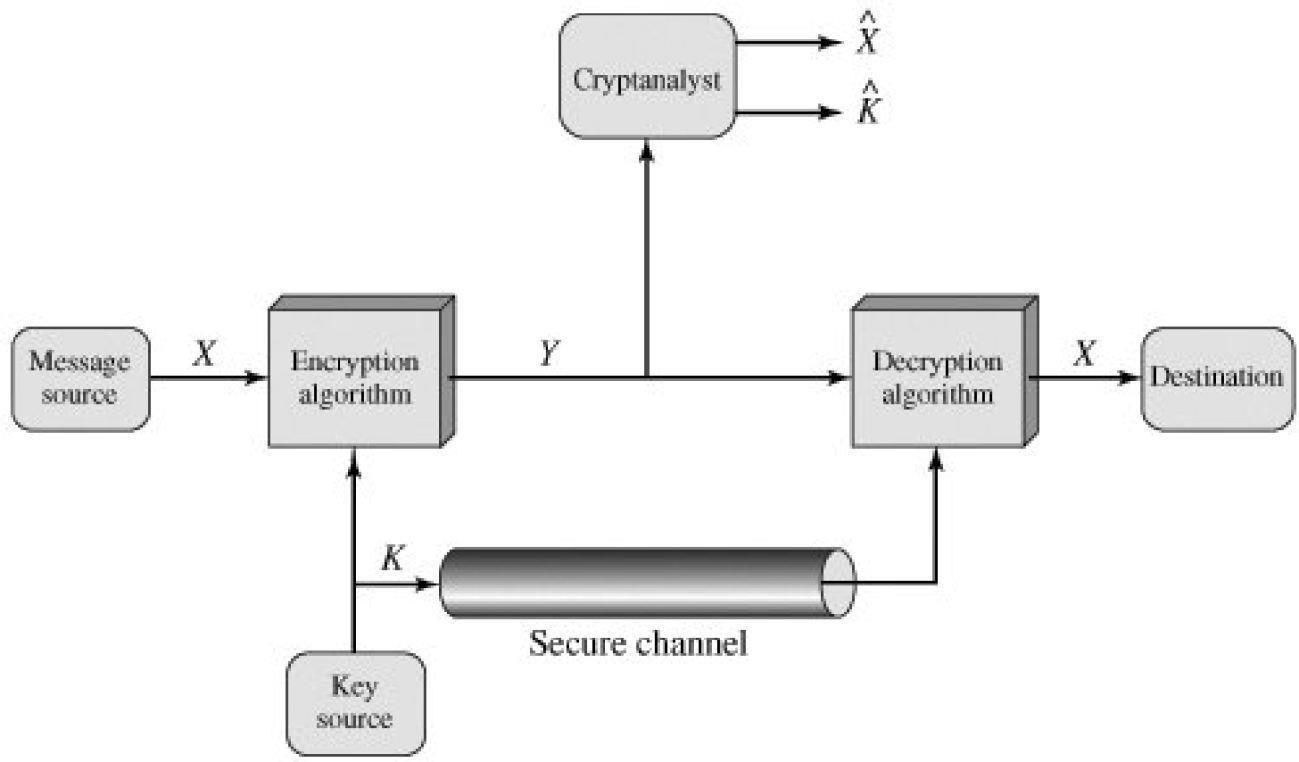

----------------------------------------------------------------------
Figure index : 5
Page         : 10
Method       : raster_xref
MIME type    : image/png
Image hash   : 17e76aafdac44f61
XRef         : 60
Caption      : 10 | P a g e Three important characteristics of this problem enabled us to use a brute-force cryptanalysis: 1. The encryption and decryption algorithms are known. 2. There are only 25 keys to try. 3. The language of the plaintext is known and easily recognizable In most networking situations, we can
Gemini summary: (not written yet - section G)


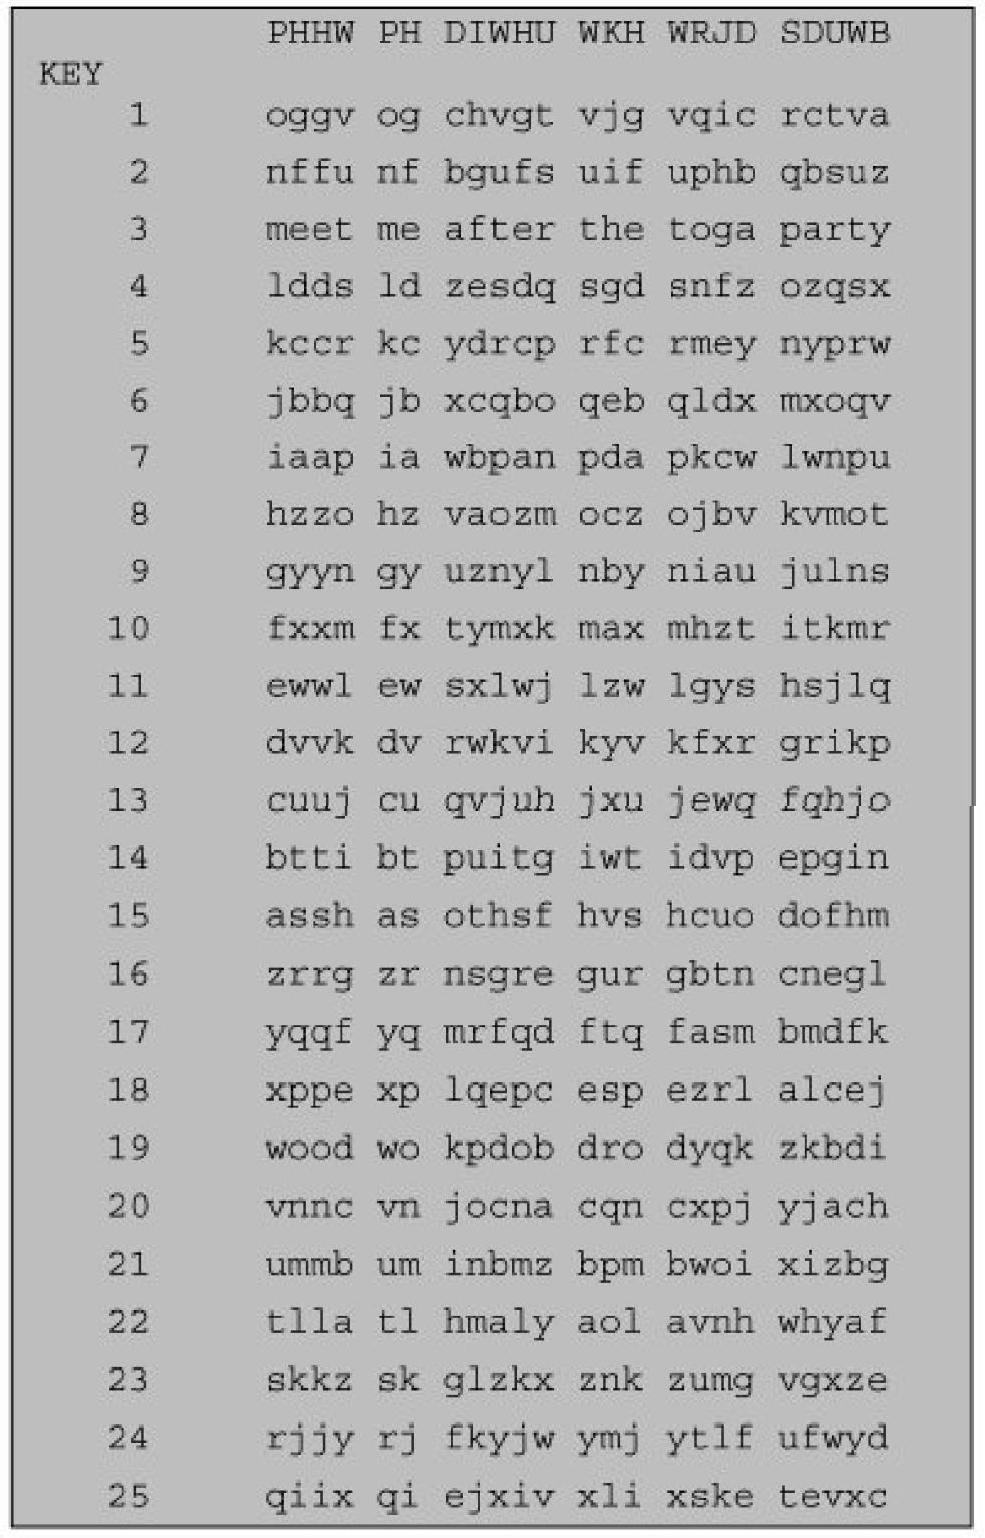

----------------------------------------------------------------------
22 further figures are available.
No raster images or vector drawings found on page 69.


In [9]:

import pymupdf


def show_image(index):
    """Display either a raster image or a vector-drawn figure."""
    record = images[index]

    with pymupdf.open(PDF_PATH) as document:
        image_bytes, mime_type = rp.figure_image_bytes(
            document,
            record,
        )

    method = record.get("extraction_method", "raster_xref")

    print(f"Figure index : {index}")
    print(f"Page         : {record.get('page_number')}")
    print(f"Method       : {method}")
    print(f"MIME type    : {mime_type}")
    print(f"Image hash   : {record.get('image_hash', '')[:16]}")

    if record.get("bbox"):
        print(f"Bounding box : {record['bbox']}")

    if record.get("xref") is not None:
        print(f"XRef         : {record['xref']}")

    print(f"Caption      : {record.get('caption', '')[:300]}")

    summary = record.get("summary")
    print(
        f"Gemini summary: "
        f"{(summary or '(not written yet - section G)')[:300]}"
    )

    display(ShowImage(data=image_bytes))


def show_images_on_page(page_number):
    """Display every extracted raster/vector figure from one PDF page."""
    indexes = [
        i for i, image in enumerate(images)
        if image.get("page_number") == page_number
    ]

    if not indexes:
        print(f"No raster images or vector drawings found on page {page_number}.")
        return

    print(f"{len(indexes)} figure records found on page {page_number}.\n")

    for index in indexes:
        show_image(index)
        print("-" * 70)


display(HTML("<h4>Extracted raster images and vector drawings</h4>"))

if not images:
    print("No figures were extracted.")
else:
    for i in range(min(6, len(images))):
        show_image(i)
        print("-" * 70)

    if len(images) > 6:
        print(f"{len(images) - 6} further figures are available.")

# Specifically inspect the ROC plots.
show_images_on_page(DRAWING_REVIEW_PAGE)


In [ ]:
# Full-page renders, for comparison only. These are NOT indexed and are never
# sent to a model - they exist so you can see where each figure came from.
display(HTML("<h4>Original PDF pages &mdash; context only, never indexed</h4>"))
figure_pages = sorted({im.get("page_number") for im in images if im.get("page_number")})
for page in figure_pages[:3]:
    print(f"page {page}")
    rendered = render_page(page)
    if rendered is not None:
        display(ShowImage(data=rendered))

## F. Extraction quality review gate

Check sections C-E before enabling model calls: a bad extraction costs a re-index and a Gemini call per figure.

In [11]:
print(f"RUN_MODEL_CALLS            = {RUN_MODEL_CALLS}")
print(f"EXTRACTION_REVIEW_APPROVED = {EXTRACTION_REVIEW_APPROVED}")
print()
if MODELS_ENABLED:
    print(f"Sections G, H and I will call Gemini ({rp.ANSWER_MODEL}).")
    print(f"Budget for a full pass: 1 (section G) + {len(images)} figures "
          f"(section H) + 2 per question (section I) = {len(images) + 3} requests.")
    print("The free tier caps requests per day per model, so count these.")
else:
    print("Sections G, H and I are inert. Nothing will be sent to any API.")
    print("To enable them, set both flags to True in section A and re-run it.")

RUN_MODEL_CALLS            = True
EXTRACTION_REVIEW_APPROVED = True

Sections G, H and I will call Gemini (gemini-flash-lite-latest).
Budget for a full pass: 1 (section G) + 28 figures (section H) + 2 per question (section I) = 31 requests.
The free tier caps requests per day per model, so count these.


## G. Figure summarisation

One Gemini vision call on a sample figure, to check description quality.

In [12]:
if not MODELS_ENABLED:
    print(SKIP_NOTE)

elif not images:
    print("No figures to summarise.")

else:
    vector_sample = next(
        (
            image for image in images
            if image.get("extraction_method") == "vector_drawing"
        ),
        None,
    )

    sample_record = vector_sample if vector_sample is not None else images[0]
    sample_images = [dict(sample_record)]

    with pymupdf.open(PDF_PATH) as document:
        rp._summarise_images(document, sample_images)

    record = sample_images[0]

    print(f"Page       : {record['page_number']}")
    print(f"Method     : {record.get('extraction_method', 'raster_xref')}")
    print(f"Xref       : {record.get('xref', 'N/A')}")
    print(f"Bounding box: {record.get('bbox', 'N/A')}")
    print(f"Caption    : {record['caption'][:300]}")
    print(f"Description:\n{record.get('summary', 'No summary generated.')}")

Page       : 1
Method     : raster_xref
Xref       : 17
Bounding box: N/A
Caption    : MODULE 1 1 | P a g e Model for Network Security When two parties (called principals) exchange a message over the Internet, a logical information channel is established using communication protocols like TCP/IP. Security becomes necessary to guard this communication from opponents who may attempt to 
Description:
The image contains a table or syllabus document with the following text: Top header row: - "Module-1" - "10 hours" Body text: - "A model for Network Security, Classical encryption techniques: Symmetric cipher model, Substitution ciphers-Caesar Cipher, Monoalphabetic Cipher, Playfair Cipher, Hill Cipher, Polyalphabetic Ciphers, One time pad, Steganography." - "Block Ciphers and Data Encryption Standards: Traditional Block Cipher structures, data Encryption Standard (DES), A DES Example, The strength of DES, Block cipher design principles." - "Chapter 1: 1.8" - "Chapter 3: 3.1, 3.2, 3.5" - "Cha

In [13]:
if not MODELS_ENABLED or not images:
    print(SKIP_NOTE if not MODELS_ENABLED else "no figures to record")
else:
    # The parent record and the deterministic id for one of each content type,
    # before anything is stored.
    sample = rp.plan_records(
        texts[:1], tables[:1], sample_images, source_id=PDF_PATH.name
    )
    parents = rp.collect_records(sample, source=PDF_PATH.name)

    for record, parent in zip(sample, parents):
        print(f"content_type     : {parent.metadata.get(rp.CONTENT_TYPE_KEY)}")
        print(f"page             : {parent.metadata.get('page_number')}")
        print(f"locator          : {record['locator']}")
        print(f"id               : {record['id'][:16]}...")
        # Parent and child carry the same text: nothing stands between the
        # record and the index, so what you read is what gets embedded.
        print(f"embedded text    : {parent.page_content[:200]}")
        print()

content_type     : text
page             : 1
locator          : BCS703_module_1.pdf|text|p1|#0
id               : dd7e5c50cfa3358e...
embedded text    : 1 | P a g e 
 
 
 
 
MODULE 1 
 
 
Model for Network Security 
When two parties (called principals) exchange a message over the Internet, a logical 
information channel is established using communicat

content_type     : table
page             : 7
locator          : BCS703_module_1.pdf|table|p7|#0
id               : 07d0c1294a3a002a...
embedded text    : e that the opponent does know the algorithm used for encryption. One possible attack under these circumstances is the brute-force approach of trying all possible keys. If the key space is very large, 

content_type     : image
page             : 1
locator          : BCS703_module_1.pdf|image|p1|#0
id               : b25a77d5b69b6c9d...
embedded text    : The image contains a table or syllabus document with the following text: Top header row: - "Module-1" - "10 hours" Body text: - "A mo

## H. Persistent indexing and retrieval

Incremental ingestion into Chroma + SQLite: an unchanged PDF is skipped, and only changed records are re-embedded.

In [14]:
if not MODELS_ENABLED:
    print(SKIP_NOTE)
else:
    if retriever is None:
        retriever = rp.build_retriever()
    elif not isinstance(retriever.docstore, rp.SQLiteStore):
        # Section A reloads rag_pipeline, so a retriever kept from before the reload
        # holds a docstore of the old SQLiteStore class. Reopen the same SQLite file
        # with the current class; the Chroma vectorstore and its client are kept.
        stale = retriever.docstore
        retriever.docstore = rp.SQLiteStore(getattr(stale, "path", rp.STATE_DB))

    report = None  # a failed run must not leave the previous report looking current
    report = rp.ingest_pdf(PDF_PATH, retriever)
    print(f"source               : {report.source_id}")
    print(f"newly indexed        : {report.indexed}")
    print(f"reused unchanged     : {report.reused}")
    print(f"deleted (stale/gone) : {report.deleted}")
    print(f"orphans reconciled   : {report.orphans_removed}")
    print(f"source skipped whole : {report.skipped}")

d:\MultimodalRAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2712.00it/s]


source               : BCS703_module_1.pdf
newly indexed        : 138
reused unchanged     : 0
deleted (stale/gone) : 0
orphans reconciled   : 0
source skipped whole : False


In [15]:
if report is None:
    print(SKIP_NOTE)
else:
    store = retriever.docstore
    ids = list(store.manifest(report.source_id))
    print(f"{len(ids)} parent records in {rp.STATE_DB.name}\n")

    for key in ids[:3]:
        parent = store.mget([key])[0]
        child = retriever.vectorstore.get(ids=[key], include=["documents", "metadatas"])
        child_text = (child["documents"] or [""])[0] or ""
        child_meta = (child["metadatas"] or [{}])[0] or {}
        print(f"id {key[:16]}...")
        print(f"  content_type      : {parent.metadata.get(rp.CONTENT_TYPE_KEY)}")
        print(f"  source / page     : {parent.metadata.get('source')} / "
              f"{parent.metadata.get('page_number')}")
        print(f"  child {rp.ID_KEY:<11} : {str(child_meta.get(rp.ID_KEY, ''))[:16]}...")
        print(f"  child (embedded)  : {child_text[:140]}")
        print(f"  parent (returned) : {parent.page_content[:140]}")
        print()

138 parent records in rag_state.sqlite3

id dd7e5c50cfa3358e...
  content_type      : text
  source / page     : BCS703_module_1.pdf / 1
  child doc_id      : dd7e5c50cfa3358e...
  child (embedded)  : 1 | P a g e 
 
 
 
 
MODULE 1 
 
 
Model for Network Security 
When two parties (called principals) exchange a message over the Internet, a 
  parent (returned) : 1 | P a g e 
 
 
 
 
MODULE 1 
 
 
Model for Network Security 
When two parties (called principals) exchange a message over the Internet, a 

id 32f9a31bf7acb096...
  content_type      : text
  source / page     : BCS703_module_1.pdf / 2
  child doc_id      : 32f9a31bf7acb096...
  child (embedded)  : 2 | P a g e 
 
 
 
 
unknown to the opponent. 
In some cases, a trusted third party is involved: 
• For distributing secret keys securely 
•
  parent (returned) : 2 | P a g e 
 
 
 
 
unknown to the opponent. 
In some cases, a trusted third party is involved: 
• For distributing secret keys securely 
•

id 44b29e7defeb1346...
  cont

In [16]:
if report is None:
    print(SKIP_NOTE)
else:
    print(f"question: {QUESTION}\n")

    # Retrieve chunks and keep only those from the current PDF
    docs = retriever.invoke(QUESTION)

    current_pdf = PDF_PATH.name
    docs = [
        doc for doc in docs
        if Path(str((doc.metadata or {}).get("source", ""))).name == current_pdf
    ]

    if not docs:
        print(f"No matching chunks found in {current_pdf}.")
    else:
        print(f"Retrieved {len(docs)} chunks from {current_pdf}:\n")

        for doc in docs:
            meta = doc.metadata or {}
            print(
                f"{str(meta.get(rp.CONTENT_TYPE_KEY)):6} "
                f"page={meta.get('page_number')} "
                f"source={meta.get('source')}"
            )
            print(f"   {doc.page_content[:160]}\n")

question: LinearCongruential Generators

No matching chunks found in BCS703_module_1.pdf.


## I. Answer generation

Gemini grades the retrieved blocks, then answers only from the ones it kept.

In [17]:
if report is None:
    print(SKIP_NOTE)
else:
    model = rp.chat_model()
    retrieved = rp.parse_docs(retriever.invoke(QUESTION))
    kwargs = {"context": retrieved, "question": QUESTION}

    # Call 1: the grader. Shown on its own so you can see what it threw away.
    graded = rp.grade_context(kwargs, model)
    print("CORRECTIVE RAG - retrieved, then kept")
    for bucket in retrieved:
        kept_pages = [d.metadata.get("page_number") for d in graded["context"][bucket]]
        all_pages = [d.metadata.get("page_number") for d in retrieved[bucket]]
        print(f"  {bucket:7} retrieved pages {all_pages} -> kept {kept_pages}")
    print()

    # Call 2: the answer, from what survived - or no call at all.
    answer = rp.answer_question(kwargs, model)
    print("QUESTION")
    print(f"  {QUESTION}\n")
    print("ANSWER")
    print(answer)
    if answer == rp.ABSTAIN_ANSWER:
        print("\n(the grader kept nothing, so no answer call was made)")

CORRECTIVE RAG - retrieved, then kept
  texts   retrieved pages [18, 81, 18, 83] -> kept []
  tables  retrieved pages [] -> kept []
  images  retrieved pages [] -> kept []

QUESTION
  LinearCongruential Generators

ANSWER
The retrieved evidence does not contain the answer to this question.

(the grader kept nothing, so no answer call was made)


## J. Live demo - five questions

Text, text, table, figure, and a question the document cannot answer - each with its answer, top relevant chunks and the retrieved figure.

ANSWER
Based on the provided evidence, the Simplified Model of Conventional Encryption (also referred to as a symmetric encryption scheme) involves the following ingredients and model elements:

* **Plaintext:** The original intelligible message or data fed into the algorithm as input (`BCS703_module_1.pdf`, page 3). A source produces a message in plaintext denoted as $X = [X_1, X_2, ..., X_M]$, where the elements are typically from the binary alphabet $\{0, 1\}$ (`BCS703_module_1.pdf`, page 5).
* **Encryption algorithm:** Performs various substitutions and transformations on the plaintext (`BCS703_module_1.pdf`, page 3). The exact substitutions and transformations depend on the specific key being used at the time, producing a different output depending on the key (`BCS703_module_1.pdf`, page 4). 
* **Secret key:** A value independent of the plaintext and of the algorithm, which is also input to the encryption algorithm (`BCS703_module_1.pdf`, pages 3–4). In the model, the secret key i

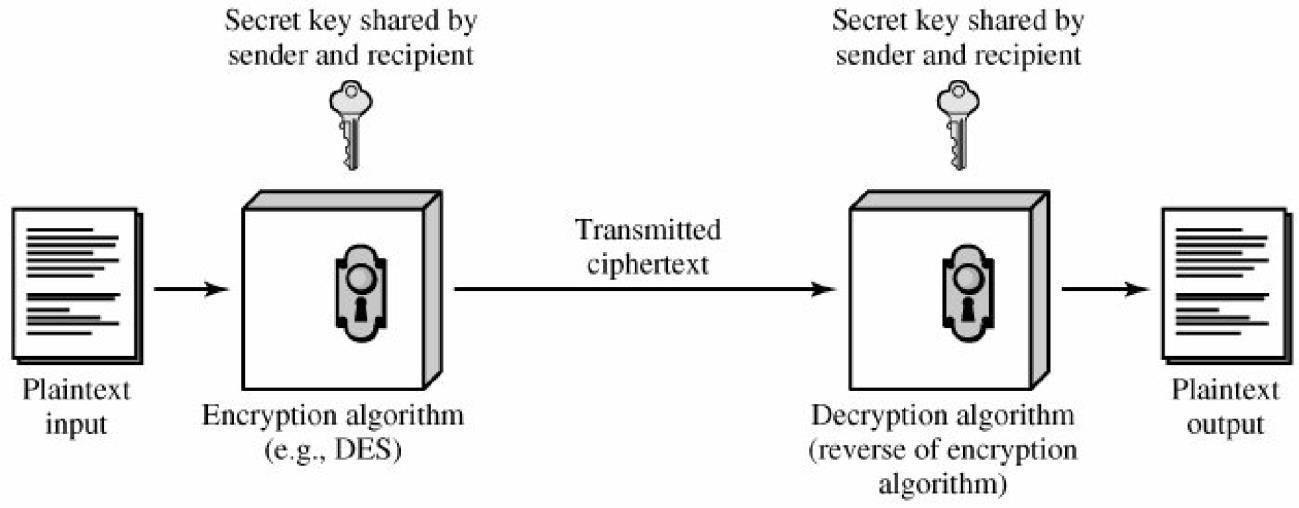

------------------------------------------------------------------------------


ANSWER
Based on the provided evidence, the model for network security operates when two parties (principals) exchange a message over the Internet through a logical information channel established by communication protocols like TCP/IP (BCS703_module_1.pdf, p. 1). 

Security is necessary to guard this communication from opponents who may attempt to compromise confidentiality, authenticity, or integrity (BCS703_module_1.pdf, p. 1). To achieve security, two components are typically used:
1. **Security Transformation:** (e.g., encryption scrambles the message, and authentication codes verify sender identity) (BCS703_module_1.pdf, p. 1).
2. **Secret Information:** (e.g., shared encryption keys used to secure and decode messages, which must remain secret) (BCS703_module_1.pdf, p. 1).

**Model Diagram & Pipeline Order (Figure 1.5):**
* **Sender Pipeline:** Starts with a "Message," which goes through a "Security-related transformation" (influenced by "Secret information"), turning it into a "S

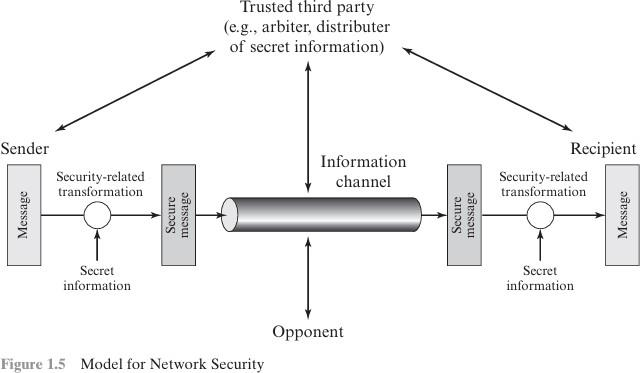

------------------------------------------------------------------------------


ANSWER
Based on the provided evidence, the Data Encryption Standard (DES) model has the following characteristics:

* **Adoption and Terminology:** It is the most widely used encryption scheme, adopted in 1977 by the National Bureau of Standards (now NIST) as FIPS PUB 46, and the algorithm itself is referred to as the Data Encryption Algorithm (DEA) (BCS703_module_1.pdf, p. 32).
* **Inputs and Outputs:** DES encrypts data in 64-bit blocks using a 56-bit key (BCS703_module_1.pdf, pp. 32, 33). It transforms a 64-bit input in a series of steps into a 64-bit output (ciphertext), and the same steps with the same key are used to reverse the encryption (BCS703_module_1.pdf, pp. 33, 32).
* **Structural Phases of Encryption:** The processing of the plaintext proceeds in three phases:
  1. The 64-bit plaintext passes through an initial permutation (IP) to rearrange the bits and produce a permuted input (BCS703_module_1.pdf, p. 33).
  2. This is followed by 16 rounds of the same function, which i

ANSWER
Based on the provided evidence, for fewer than 100K samples (`<100K samples` connected via a green arrow labeled `YES` from `predicting a category`), the recommended classifier is **Linear SVC** (The Hundred Page Machine Learning BOOK.pdf, p. 60).

TOP CHUNKS (kept by the relevance grader)
[1] image | The Hundred Page Machine Learning BOOK.pdf | page 60
    The image is a flowchart titled "scikit-learn algorithm cheat-sheet" originating from "START". It is divided into four main colored regions: "classification" (pink/red), "regression" (light blue), "clustering" (light purple), and "dimensionality reduction" (light yellow/tan). ###...

RETRIEVED FIGURE: The Hundred Page Machine Learning BOOK.pdf | page 60 | raster_xref


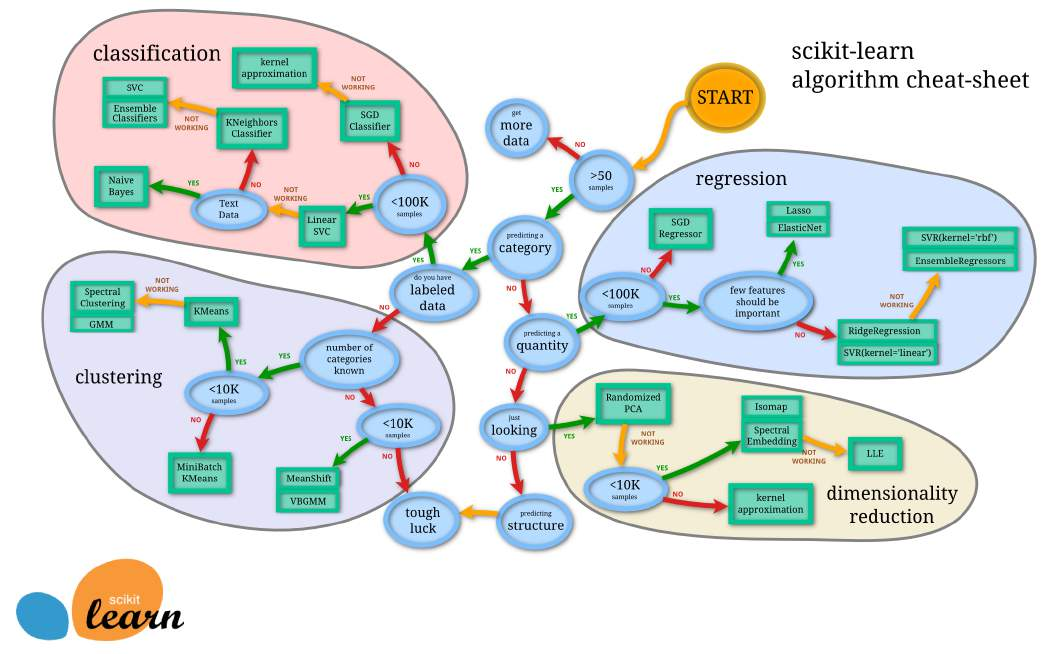

------------------------------------------------------------------------------


ANSWER
The retrieved evidence does not contain the answer to this question.

TOP CHUNKS (kept by the relevance grader)
None - the grader judged all 4 retrieved chunks irrelevant.

No relevant figure was retrieved for this question.
------------------------------------------------------------------------------


In [20]:
# Five live questions against the index section H built. Reuses `retriever` and the
# stored figure descriptions: no ingestion, no re-embedding, no figure re-summarising.
import pymupdf
from IPython.display import HTML, Image as ShowImage, display

DEMO_QUESTIONS = [
    ("text", "tell me about the Simplified Model of Conventional Encryption"),
    ("text", "explain in brief about the model for network security with its relevant diagram"),
    ("table", "Tell me about the DES model"),
    ("figure", "In the scikit-learn algorithm cheat-sheet flowchart, which classifier "
               "is recommended for labeled data with fewer than 100K samples?"),
    # Checked absent: no "RLHF", "human feedback" or "ChatGPT" in the text of either
    # indexed PDF, nor in any stored figure description.
    ("not in the document", "What does the document say about reinforcement learning "
                            "from human feedback (RLHF), the technique used to train ChatGPT?"),
]
DEMO_CHUNKS = 2
DEMO_PREVIEW_CHARS = 280


def show_figure(doc):
    """Render a retrieved figure record - raster (xref) or vector (bbox) - from its own PDF."""
    meta = doc.metadata or {}
    pdf = PROJECT_DIR / str(meta.get("source") or "")
    if not pdf.is_file():
        print(f"(source PDF {meta.get('source')!r} not found, figure not rendered)")
        return
    try:
        with pymupdf.open(pdf) as document:
            data, _ = rp.figure_image_bytes(document, meta)
    except Exception as exc:  # e.g. a record missing its xref or bbox
        print(f"(figure not rendered: {type(exc).__name__}: {exc})")
        return
    method = meta.get("extraction_method") or "raster_xref"
    print(f"RETRIEVED FIGURE: {meta.get('source')} | page {meta.get('page_number')} | {method}")
    display(ShowImage(data=data, width=520))


if not MODELS_ENABLED:
    print(SKIP_NOTE)
else:
    if retriever is None:  # fresh kernel: reopen the persisted index, as section H does
        retriever = rp.build_retriever()
    model = rp.chat_model()

    for number, (kind, question) in enumerate(DEMO_QUESTIONS, start=1):
        display(HTML(f"<h3>Q{number} &middot; {kind}</h3><p><b>{question}</b></p>"))
        docs = retriever.invoke(question)
        kwargs = {"context": rp.parse_docs(docs), "question": question}
        try:
            # The two steps of rp.answer_question, kept apart so the grader's verdict
            # also decides which chunks and which figure are shown as relevant.
            graded = rp.grade_context(kwargs, model)
            kept = {id(d) for group in graded["context"].values() for d in group}
            answer = model.invoke(rp.build_prompt(graded)).text if kept else rp.ABSTAIN_ANSWER
            relevant, label = [d for d in docs if id(d) in kept], "kept by the relevance grader"
        except Exception as exc:  # quota or network: still show what retrieval found
            answer = f"(Gemini call failed - {type(exc).__name__}: {exc})"
            relevant, label = docs, "retrieved, not graded"

        print("ANSWER")
        print(answer.strip())

        print(f"\nTOP CHUNKS ({label})")
        for rank, doc in enumerate(relevant[:DEMO_CHUNKS], start=1):
            meta = doc.metadata or {}
            body = " ".join((doc.page_content or "").split())
            print(f"[{rank}] {meta.get(rp.CONTENT_TYPE_KEY, 'unknown')} | "
                  f"{meta.get('source', 'unknown source')} | page {meta.get('page_number', '?')}")
            print(f"    {body[:DEMO_PREVIEW_CHARS]}{'...' if len(body) > DEMO_PREVIEW_CHARS else ''}")
        if not relevant:
            print(f"None - the grader judged all {len(docs)} retrieved chunks irrelevant.")

        figures = [d for d in relevant if (d.metadata or {}).get(rp.CONTENT_TYPE_KEY) == "image"]
        if figures:
            print()
            show_figure(figures[0])
        else:
            print("\nNo relevant figure was retrieved for this question.")
        print("-" * 78)